# Análise Não Linear de Dano Progressivo na Interface (PID) via DBEM 2D Coesivo
## Reprodução da Fig. 26: Curva Força–Deslocamento para Descolamento Assimétrico ($h_s = 1.08\text{ mm}$)

Este Jupyter Notebook apresenta o **passo a passo detalhado** para configurar, executar e pós-processar uma **análise não linear de propagação de dano coesivo (*Progressive Interface Damage* — PID)** utilizando o **Método dos Elementos de Contorno Dual Multidomínio 2D (`MAIN_COHESIVE_DBEM_2D`)** paralelizado com **OpenMP**.

O notebook é **multiplataforma**, podendo ser executado tanto localmente (**Windows / Linux / macOS** no VSCode ou JupyterLab) quanto no **Google Colab (Ubuntu Linux)**.

---
### Artigo de Referência
> *Comparative analysis of adhesive debonding in three-point bending tests using boundary element methods: Coupled criterion versus interface damage model*,  
> S. G. F. Cordeiro, T. V. Birro, R. Q. Rodriguez, E. L. Albuquerque, L. S. Campos, J. F. U. Vivero, É. Paroissien, M. Aufray, F. Lachaud.  
> **Engineering Analysis with Boundary Elements (EABE)**, vol. 180, 106474, 2025.

---
### Roteiro Passo a Passo da Análise Não Linear
1. **Preparação do Ambiente**: Detecção automática do sistema operacional (Local ou Google Colab), compilador `gfortran` (OpenMP + LAPACK/BLAS) e bibliotecas Python (`numpy`, `matplotlib`, `meshio`, `gmsh`).
2. **Fundamentação Teórica e Numérica da Análise Não Linear**:
   - Lei de tração-separação bilinear em Modo Misto (Seções 4.4 e 5.5);
   - Evolução da variável escalar de dano $D(\delta) \in [0, 1]$ e degradação da matriz de rigidez interfacial $\mathbf{K}_c(\boldsymbol{\Delta}_c)$;
   - Método de continuação por **controle de deslocamento** com preditor-corretor de **Newton-Raphson** ($\Delta \mathbf{X}_i = \Delta \mathbf{X}_i^c - \Delta \lambda_i \Delta \mathbf{X}_i^p$);
   - Modelagem do **descolamento assimétrico (`ANALYSIS_TYPE = 'CA'`)** conforme a Seção 6.3.2 do artigo.
3. **Compilação do Solver Fortran Paralelizado (`OpenMP`)**: Compilação otimizada (`-O3 -fopenmp`) do executável `MAIN_COHESIVE_DBEM_2D`.
4. **Geometria Paramétrica (`.geo`) e Critério de Refinamento da Zona Coesiva**: Verificação do comprimento característico de fratura $L_c$ (Martin et al.) e geração da malha `.msh` no **Gmsh**.
5. **Pré-Processamento Não Linear com `meshio`**:
   - Identificação automática do **nó estrutural controlado** (`CONTROLED_NODE`) no topo central do substrato e do **nó coesivo monitorado** (`COHESIVE_NODE`) na quina da interface;
   - Prescrição das condições de contorno para controle de deslocamento (apoio rolete à esquerda, apoio fixo à direita e tração unitária de referência $\overline{t}_y = -1.0\text{ MPa}$ escalonada pelo fator de carga $\lambda$);
   - Geração dos 5 arquivos `.txt` na pasta `sim_fig26_nlinear/` e inspeção visual da malha e condições de contorno.
6. **Execução Incremental do Solver Não Linear**: Solução passo a passo do carregamento controlado por deslocamento e análise de desempenho.
7. **Pós-Processamento e Geração da Fig. 26**:
   - Reprodução da **Fig. 26** (*Force–displacement results for asymmetric debonding: $h_s = 1.08\text{ mm}$*, curva **2D BEM - PID**);
   - Visualização complementar da evolução do comprimento da trinca assimétrica $a(u)$ (comparável à **Fig. 30** do artigo) e da frente de degradação de rigidez $K_{nn}/k_{n0}$ ao longo da interface.

## Passo 0: Preparação do Ambiente (Local e Google Colab)

A célula abaixo verifica o ambiente de execução:
- **No Google Colab (Linux)**: instala automaticamente o compilador `gfortran`, as bibliotecas matriciais `liblapack-dev` e `libblas-dev`, o gerador de malhas `gmsh` via `apt-get`, e os pacotes Python `meshio` e `gmsh`.
- **No Ambiente Local (Windows / Linux)**: verifica os pacotes Python no ambiente virtual e configura automaticamente o `PATH` para o compilador `gfortran` (MSYS2 UCRT64 no Windows ou `/usr/bin` no Linux).

In [1]:
import os
import sys
import time
import shutil
import platform
import subprocess
import importlib

# 1. Detecção do Google Colab
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    print("[*] Ambiente Google Colab detectado!")
    print("[*] Instalando gfortran, LAPACK/BLAS e Gmsh via apt-get...")
    subprocess.run(
        "apt-get update -qq && apt-get install -y -qq gfortran liblapack-dev libblas-dev gmsh",
        shell=True, check=True
    )

# 2. Verificação de pacotes Python necessários
required_packages = ['numpy', 'matplotlib', 'meshio', 'gmsh']
missing_packages = []
for pkg in required_packages:
    try:
        importlib.import_module(pkg)
    except ImportError:
        missing_packages.append(pkg)

if missing_packages:
    print(f"[*] Instalando pacotes Python ausentes: {missing_packages}...")
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing_packages])
    importlib.invalidate_caches()

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

# 3. Ajuste de diretório de trabalho e PATH do compilador no Windows/Linux
if os.path.basename(os.getcwd()) != 'COHESIVE_DBEM_2D_14_03' and os.path.isdir('COHESIVE_DBEM_2D_14_03'):
    os.chdir('COHESIVE_DBEM_2D_14_03')

if platform.system() == 'Windows':
    msys_bins = [r"C:\msys64\ucrt64\bin", r"C:\msys64\usr\bin"]
    for b in msys_bins:
        if os.path.isdir(b) and b not in os.environ.get("PATH", ""):
            os.environ["PATH"] = os.environ.get("PATH", "") + os.pathsep + b

os.environ["OMP_NUM_THREADS"] = str(os.cpu_count() or 8)
print(f"[+] Diretório ativo: {os.getcwd()}")
print(f"[+] Sistema: {platform.system()} | Threads OpenMP configuradas: {os.environ['OMP_NUM_THREADS']}")

[+] Diretório ativo: c:\Users\Adm\OneDrive - unb.br\Antigravity\Adhesives\COHESIVE_DBEM_2D_14_03
[+] Sistema: Windows | Threads OpenMP configuradas: 8


## Passo 1: Fundamentação Teórica e Numérica da Análise Não Linear

### 1.1 Diferença entre Análise Elástica Linear (`LE`) e Propagação Coesiva Não Linear (`CP` / `CA`)
No modelo de **interface fraca (*weak interface*)**, o substrato ($\Omega_1$, contorno coesivo $\Gamma_{c-}$ ou `Im`) e o adesivo ($\Omega_2$, contorno coesivo $\Gamma_{c+}$ ou `Ip`) são acoplados por uma distribuição contínua de molas normais (Modo I, rigidez $k_n$) e tangenciais (Modo II, rigidez $k_t$):

$$\mathbf{t}_c = \mathbf{k}_c \boldsymbol{\delta}_c, \qquad \mathbf{k}_c = \mathbf{R} \begin{bmatrix} k_n(\delta) & 0 \\ 0 & k_t(\delta) \end{bmatrix} \mathbf{R}^T$$

onde $\boldsymbol{\delta} = \{\delta_n, \delta_t\}^T$ é o vetor de descontinuidade de deslocamento (salto relativo entre `Ip` e `Im`) no sistema local da interface e $\delta = \|\boldsymbol{\delta}\| = \sqrt{\delta_n^2 + \delta_t^2}$ é o deslocamento relativo equivalente.

- **Na Análise Linear (`ANALYSIS_TYPE = 'LE'`)**: assume-se interface perfeitamente íntegra ($D = 0 \implies k_n = k_{n0},\; k_t = k_{t0}$). A matriz global $\mathbf{A}$ é constante e resolve-se um único sistema linear $\mathbf{A}\mathbf{X} = \mathbf{B}$.
- **Na Análise Não Linear (`ANALYSIS_TYPE = 'CP'` ou `'CA'`)**: quando o deslocamento equivalente $\delta$ ultrapassa o limiar elástico $\delta_e$ em qualquer ponto de colocação da interface, ocorre degradação progressiva de rigidez ($D > 0$), tornando a matriz $\mathbf{A}(\mathbf{X})$ dependente do vetor de incógnitas $\mathbf{X}$.

---
### 1.2 Lei Coesiva Bilinear em Modo Misto (Seções 4.4 e 5.5 do Artigo)
Adotando a condição sem diferenciação entre os modos I e II ($k_{n0} = k_{t0}$, $\sigma_{nc} = \tau_{tc} = \sigma_c$ e $\mathcal{G}_c^I = \mathcal{G}_c^{II} = \mathcal{G}_c$), os deslocamentos relativos críticos de **início de dano ($\delta_e$)** e de **falha completa ($\delta_f$)** são dados pela Eq. (29) do artigo:

$$\delta_e = \frac{\sigma_c}{k_{n0}}, \qquad \delta_f = \frac{2\mathcal{G}_c}{\sigma_c}$$

A lei constitutiva bilinear (Eqs. 46–48 do artigo) define as trações normais ($\sigma$) e cisalhantes ($\tau$) em três regimes:

$$\sigma(\delta_n) = k_n(\delta)\,\delta_n = \begin{cases}
k_{n0}\,\delta_n, & \text{se } \delta \le \delta_e \quad \text{(Regime Elástico Íntegro)} \\[4pt]
(1 - D)\,k_{n0}\,\delta_n, & \text{se } \delta_e < \delta < \delta_f \quad \text{(Amolecimento / Softening)} \\[4pt]
k_{\text{res}}\,\delta_n, & \text{se } \delta \ge \delta_f \quad \text{(Falha Completa / Trinca Livre de Tração)}
\end{cases}$$

onde a variável escalar de dano $D(\delta) \in [0, 1]$ evolui segundo a relação hiperbólica:

$$D(\delta) = \frac{\delta_f(\delta - \delta_e)}{\delta(\delta_f - \delta_e)}$$

Para garantir a irreversibilidade termodinâmica do dano em casos de descarregamento local (*unloading/reloading*), o solver armazena o histórico máximo em cada ponto de colocação: $D_{\max, i} = \max_{t \le \tau} D_i(t)$.

---
### 1.3 Algoritmo Incremental-Iterativo de Newton-Raphson com Controle de Deslocamento (Eqs. 49–55)
Como ensaios de descolamento em juntas frágeis apresentam queda abrupta de força após o pico (*softening* estrutural), o controle de força falha no ponto limite ($F_c$). Por isso, o solver utiliza o **método de continuação por controle de deslocamento**:

1. **Vetor de Carregamento de Referência ($\overline{\mathbf{B}}$) e Fator de Carga ($\lambda$)**:
   - Na superfície de carregamento (`carga`, largura $2.0\text{ mm}$ no topo central do substrato), prescreve-se uma tração vertical de referência unitária $\overline{t}_y = -1.0\text{ MPa}$, deixando os deslocamentos verticais $u_y$ dessa região como incógnitas no vetor $\mathbf{X}$.
   - Seleciona-se o grau de liberdade $j$ correspondente ao deslocamento vertical $u_y$ do **nó central superior** (`CONTROLED_NODE` em $x = 0, y = h_s$) para controlar a análise em $N_s$ passos iguais:
     $$\Delta u_{y,\text{pres}} = \frac{U_{\max}}{N_s}$$
2. **Iterações Preditor-Corretor em Cada Passo de Carga**:
   - Para um estado não equilibrado $(\mathbf{X}_i, \lambda_i)$, o vetor resíduo é $\mathcal{R}_i = \mathbf{A}(\mathbf{X}_i)\mathbf{X}_i - \lambda_i \overline{\mathbf{B}}$.
   - Decompõe-se o incremento da solução na forma $\Delta \mathbf{X}_i = \Delta \mathbf{X}_i^c - \Delta \lambda_i \Delta \mathbf{X}_i^p$, resolvendo-se simultaneamente os dois sistemas lineares com a mesma fatoração LU (`DGETRF` + `DGETRS` do LAPACK):
     $$\mathbf{A}_i \Delta \mathbf{X}_i^c = -\mathcal{R}_i, \qquad \mathbf{A}_i \Delta \mathbf{X}_i^p = -\overline{\mathbf{B}}$$
   - Como o grau de liberdade controlado $j$ já recebeu seu incremento prescrito no início do passo, impõe-se $\mathbf{e}_j^T \Delta \mathbf{X}_i = 0$, obtendo-se o incremento do fator de carga $\Delta \lambda_i$:
     $$\Delta \lambda_i = -\frac{\mathbf{e}_j^T \Delta \mathbf{X}_i^c}{\mathbf{e}_j^T \Delta \mathbf{X}_i^p}, \qquad \mathbf{X}_{i+1} = \mathbf{X}_i + \Delta \mathbf{X}_i^c + \Delta \lambda_i \Delta \mathbf{X}_i^p, \qquad \lambda_{i+1} = \lambda_i + \Delta \lambda_i$$
   - Atualiza-se a rigidez coesiva $\mathbf{K}_c(\mathbf{X}_{i+1})$ e repete-se o ciclo até que o critério de convergência normalizado seja satisfeito:
     $$\frac{\|\mathcal{R}(\mathbf{X}_{i+1}, \lambda_{i+1})\|_2}{\|\overline{\mathbf{B}}\|_2} \le \text{tol}_{\text{Newton}}$$

---
### 1.4 Descolamento Simétrico (`CP`) vs. Descolamento Assimétrico (`CA` — Seção 6.3.2)
- Nos ensaios experimentais de flexão em 3 pontos (Seção 3.1 e Fig. 5 do artigo), a iniciação e a propagação da trinca ocorrem **assimetricamente** a partir de apenas uma das extremidades da interface (com 50% de probabilidade para o lado esquerdo ou direito).
- Como a geometria nominal e o carregamento são simétricos, uma análise perfeitamente simétrica (`ANALYSIS_TYPE = 'CP'`) nucleia duas trincas simultâneas nas duas extremidades ($x = \pm 12.5\text{ mm}$, reproduzindo a **Fig. 22**).
- Para simular o **descolamento assimétrico (`ANALYSIS_TYPE = 'CA'`)** que gera a **Fig. 26**, conforme descrito na **Seção 6.3.2 (página 15 do artigo)**, eleva-se a tensão crítica dos elementos próximos à extremidade direita da interface para $\sigma_c = 10^{50}\text{ MPa}$. Dessa forma, impede-se a nucleação espúria no canto direito e permite-se que uma única trinca inicie no canto esquerdo ($x = -12.5\text{ mm}$) e se propague livremente ao longo da interface.

## Passo 2: Compilação do Solver Fortran Paralelizado (`MAIN_COHESIVE_DBEM_2D`)

O solver `MAIN_COHESIVE_DBEM_2D` utiliza:
- **OpenMP (`-fopenmp`)** para paralelizar a integração numérica das matrizes densas $\mathbf{H}$ e $\mathbf{G}$ (`SCHEDULE(DYNAMIC)`) e a remontagem da matriz acoplada $\mathbf{A}(\mathbf{K}_c)$ a cada atualização de rigidez coesiva;
- **Cache inteligente de fatoração LU (`DGETRF` / `DGETRS`)** no módulo `MODULE_SOLVER.f90`, refatorando a matriz do operador secante apenas quando há variação significativa de rigidez coesiva na frente de dano, reduzindo drasticamente o tempo de solução não linear.

In [2]:
make_cmd = "mingw32-make" if (platform.system() == "Windows" and shutil.which("mingw32-make")) else "make"
exe_name = "MAIN_COHESIVE_DBEM_2D.exe" if platform.system() == "Windows" else "./MAIN_COHESIVE_DBEM_2D"

print(f"[*] Compilando o solver Fortran com '{make_cmd}' (-O3 -fopenmp)...")
res_make = subprocess.run([make_cmd], capture_output=True, text=True)
if res_make.returncode != 0:
    print(res_make.stdout)
    print(res_make.stderr)
    raise RuntimeError("Falha na compilação do solver Fortran.")

if platform.system() == "Windows" and os.path.exists("MAIN_COHESIVE_DBEM_2D") and not os.path.exists("MAIN_COHESIVE_DBEM_2D.exe"):
    shutil.copy2("MAIN_COHESIVE_DBEM_2D", "MAIN_COHESIVE_DBEM_2D.exe")

print(f"[+] Executável compilado e pronto: {os.path.abspath(exe_name)}")

[*] Compilando o solver Fortran com 'mingw32-make' (-O3 -fopenmp)...
[+] Executável compilado e pronto: c:\Users\Adm\OneDrive - unb.br\Antigravity\Adhesives\COHESIVE_DBEM_2D_14_03\MAIN_COHESIVE_DBEM_2D.exe


## Passo 3: Geometria Paramétrica (`.geo`), Comprimento de Zona Coesiva e Malha no Gmsh

### 3.1 Verificação do Critério de Refinamento da Zona Coesiva (Eqs. 30 e 31)
Segundo Martin et al. (2016), apresentados na **Seção 4.4 (Eqs. 30–31)** e **Seção 6.3 (página 15)** do artigo, a aplicação de modelos de zona coesiva (TSM/PID) exige que o comprimento dos elementos na interface ($L_{\text{mesh}}$) seja suficientemente pequeno para resolver a **zona de processo de fratura ($L_c$)**:

$$L_c = \frac{E_a\,\mathcal{G}_c}{\sigma_c^2}, \qquad \frac{6}{\pi}\frac{L_{\text{mesh}}}{h_s} < \frac{L_c}{h_s} \implies L_{\text{mesh}} < \frac{\pi}{6} L_c \approx 0.40\text{ mm}$$

Para o sistema com $h_s = 1.08\text{ mm}$ (**Tabela 2 e Tabela 4 — Asymmetric**):
- Módulo de Young do adesivo: $E_a = 3000\text{ MPa}$;
- Resistência crítica da interface: $\sigma_c = 44.654\text{ MPa}$;
- Tenacidade à fratura crítica: $\mathcal{G}_c = 0.520\text{ N/mm}$;
- Comprimento característico da zona coesiva:
  $$L_c = \frac{3000 \times 0.520}{(44.654)^2} \approx 0.7824\text{ mm} \implies L_{\text{mesh, max}} \approx 0.40\text{ mm}$$

Na malha paramétrica abaixo, adotamos $l_{c,\text{int}} = 0.25\text{ mm}$ (**100 elementos lineares descontínuos = 200 pontos de colocação em cada face `Im` e `Ip` da interface de $25\text{ mm}$**, densidade de 4 elementos/mm), satisfazendo rigorosamente a condição $L_{\text{mesh}} = 0.25\text{ mm} \le 0.40\text{ mm}$ com excelente eficiência computacional.

In [3]:
from gmsh_to_dbem import generate_geometry_and_mesh, compute_inodes, create_fortran_input_files
from plot_mesh_bc import read_mesh_and_bcs, show_dbem_geometry_and_bcs

# Parâmetros da Tabela 2, Tabela 3 e Tabela 4 (Asymmetric, hs = 1.08 mm)
E_a = 3000.0       # MPa
sigma_c = 44.654   # MPa
G_c = 0.520        # N/mm (ou MPa.mm)
hs_mm = 1.08       # mm
lc_int_mm = 0.25   # mm (4 elementos/mm na interface coesiva)

L_c = (E_a * G_c) / (sigma_c ** 2)
L_mesh_max = (np.pi / 6.0) * L_c

print(f"[*] Comprimento da zona de processo de fratura (Eq. 31): L_c = {L_c:.4f} mm")
print(f"[*] Tamanho máximo de elemento exigido (Eq. 30):         L_mesh <= {L_mesh_max:.4f} mm")
print(f"[*] Tamanho de elemento adotado na interface:            L_mesh =  {lc_int_mm:.4f} mm (OK!)")

# Diretório dedicado para os arquivos da simulação não linear
sim_dir = "sim_fig26_nlinear"
os.makedirs(sim_dir, exist_ok=True)
model_base = os.path.join(sim_dir, "modelo_fig10_hs108")

geo_code_hs108 = \"\"\"SetFactory("OpenCASCADE");

// Parâmetros geométricos do ensaio 3PBT (em metros) - Fig. 2 e Seção 6.1
hs = 0.00108;       // Espessura do substrato: 1.08 mm
ha = 4.0e-3;        // Espessura do bloco de adesivo: 4.0 mm
L_sub = 50.0e-3;    // Comprimento do substrato: 50.0 mm
L_adh = 25.0e-3;    // Comprimento da interface colada: 25.0 mm
d_supp = 35.90e-3;  // Distância entre os centros dos apoios: 35.90 mm
w_supp = 0.12e-3;   // Largura de cada apoio: 0.12 mm
w_load = 2.0e-3;    // Largura da região de aplicação de carga central: 2.0 mm

x_sub = L_sub / 2.0;
x_adh = L_adh / 2.0;
x_s_c = d_supp / 2.0;
x_s1 = x_s_c - w_supp / 2.0;
x_s2 = x_s_c + w_supp / 2.0;
x_l = w_load / 2.0;

// Tamanhos característicos dos elementos de contorno (em metros)
lc_int  = 0.00025;  // 0.25 mm na interface coesiva (100 elementos em 25 mm)
lc_ext  = 1.0e-3;   // 1.00 mm nos contornos livres externos
lc_supp = 0.06e-3;  // 0.06 mm nos apoios (2 elementos por apoio)
lc_load = 0.5e-3;   // 0.50 mm na região de carga (4 elementos em 2.0 mm)

// --- Sub-região 1: Substrato (y = 0 até hs) ---
p1  = newp; Point(p1)  = {-x_sub, 0, 0, lc_ext};
p2  = newp; Point(p2)  = {-x_s2,  0, 0, lc_supp};
p3  = newp; Point(p3)  = {-x_s1,  0, 0, lc_supp};
p4  = newp; Point(p4)  = {-x_adh, 0, 0, lc_int};
p5  = newp; Point(p5)  = { x_adh, 0, 0, lc_int};
p6  = newp; Point(p6)  = { x_s1,  0, 0, lc_supp};
p7  = newp; Point(p7)  = { x_s2,  0, 0, lc_supp};
p8  = newp; Point(p8)  = { x_sub, 0, 0, lc_ext};

p9  = newp; Point(p9)  = { x_sub, hs, 0, lc_ext};
p10 = newp; Point(p10) = { x_l,   hs, 0, lc_load};
p11 = newp; Point(p11) = {-x_l,   hs, 0, lc_load};
p12 = newp; Point(p12) = {-x_sub, hs, 0, lc_ext};

l_sub_bot1 = newl; Line(l_sub_bot1) = {p1, p2};
l_supp_esq = newl; Line(l_supp_esq) = {p2, p3};
l_sub_bot2 = newl; Line(l_sub_bot2) = {p3, p4};
l_int_m    = newl; Line(l_int_m)    = {p4, p5}; // Interface Im (Substrato)
l_sub_bot3 = newl; Line(l_sub_bot3) = {p5, p6};
l_supp_dir = newl; Line(l_supp_dir) = {p6, p7};
l_sub_bot4 = newl; Line(l_sub_bot4) = {p7, p8};

l_sub_dir  = newl; Line(l_sub_dir)  = {p8, p9};
l_sub_top1 = newl; Line(l_sub_top1) = {p9, p10};
l_load     = newl; Line(l_load)     = {p10, p11}; // Região de carregamento
l_sub_top2 = newl; Line(l_sub_top2) = {p11, p12};
l_sub_esq  = newl; Line(l_sub_esq)  = {p12, p1};

Curve Loop(1) = {l_sub_bot1, l_supp_esq, l_sub_bot2, l_int_m, l_sub_bot3, l_supp_dir, l_sub_bot4, l_sub_dir, l_sub_top1, l_load, l_sub_top2, l_sub_esq};
Plane Surface(1) = {1};

// --- Sub-região 2: Adesivo (y = -ha até 0) ---
p13 = newp; Point(p13) = { x_adh, 0, 0, lc_int};
p14 = newp; Point(p14) = {-x_adh, 0, 0, lc_int};
p15 = newp; Point(p15) = {-x_adh, -ha, 0, lc_ext};
p16 = newp; Point(p16) = { x_adh, -ha, 0, lc_ext};

l_int_p    = newl; Line(l_int_p)    = {p13, p14}; // Interface Ip (Adesivo)
l_adh_esq  = newl; Line(l_adh_esq)  = {p14, p15};
l_adh_bot  = newl; Line(l_adh_bot)  = {p15, p16};
l_adh_dir  = newl; Line(l_adh_dir)  = {p16, p13};

Curve Loop(2) = {l_int_p, l_adh_esq, l_adh_bot, l_adh_dir};
Plane Surface(2) = {2};

// Discretização uniforme transfinita ao longo da interface coesiva
n_int = Ceil(L_adh / lc_int) + 1;
Transfinite Curve {l_int_m, l_int_p} = n_int Using Progression 1;

// Grupos Físicos de Contorno (1D)
Physical Curve("contorno_livre_sub") = {l_sub_bot1, l_sub_bot2, l_sub_bot3, l_sub_bot4, l_sub_dir, l_sub_top1, l_sub_top2, l_sub_esq};
Physical Curve("apoio_esq")           = {l_supp_esq};
Physical Curve("apoio_dir")           = {l_supp_dir};
Physical Curve("carga")               = {l_load};
Physical Curve("interface_m")         = {l_int_m};
Physical Curve("interface_p")         = {l_int_p};
Physical Curve("contorno_livre_adh") = {l_adh_esq, l_adh_bot, l_adh_dir};

// Grupos Físicos de Superfície (2D)
Physical Surface("subregion_1") = {1};
Physical Surface("subregion_2") = {2};
\"\"\"

generate_geometry_and_mesh(model_base, geo_code_hs108)

[*] Comprimento da zona de processo de fratura (Eq. 31): L_c = 0.7824 mm
[*] Tamanho máximo de elemento exigido (Eq. 30):         L_mesh <= 0.4097 mm
[*] Tamanho de elemento adotado na interface:            L_mesh =  0.2500 mm (OK!)
[Gmsh] Arquivo de geometria gravado: 'sim_fig26_nlinear\modelo_fig10_hs108.geo'
[Gmsh] Gerando malha 2D a partir de 'sim_fig26_nlinear\modelo_fig10_hs108.geo'...
[Gmsh] Malha gerada com sucesso via API Python gmsh: 'sim_fig26_nlinear\modelo_fig10_hs108.msh'


## Passo 4: Pré-Processamento Não Linear com `meshio` e Configuração dos 5 Arquivos `.txt`

Para uma análise não linear (`ANALYSIS_TYPE = 'CA'` ou `'CP'`), os 5 arquivos de entrada exigem cuidados específicos que diferem da análise linear:

### 4.1 Propriedades dos Materiais (`2_MATERIALS.txt`)
- **Sub-região 1 (Substrato — Alumínio 2024-T3 com ajuste de largura $b_1/b_2 = 10\text{ mm}/5\text{ mm} = 2$)**:
  $$E_1 = 2 \times 68\,000 = 136\,000\text{ MPa}, \qquad \nu_1 = 0.33$$
- **Sub-região 2 (Adesivo — DGEBA/DETA/Organosilane)**:
  $$E_2 = 3\,000\text{ MPa}, \qquad \nu_2 = 0.35$$
- **Propriedades Coesivas da Interface (Tabela 3 e Tabela 4 — Asymmetric, convertidas para unidades consistentes $\text{MPa}$ e $\text{m}$)**:
  - Rigidez inicial: $k_{n0} = k_{t0} = 2000\text{ MPa/mm} = 2.0 \times 10^6\text{ MPa/m}$;
  - Energia crítica de fratura: $\mathcal{G}_c = 0.520\text{ N/mm} = 0.000520\text{ MPa}\cdot\text{m}$ (`phin = phit = 5.20D-04`);
  - Tensão crítica: $\sigma_c = \tau_c = 44.654\text{ MPa}$ (`smax = tmax = 44.654D0`).

### 4.2 Condições de Contorno para Controle de Deslocamento (`3_BOUNDARY_CONDITIONS.txt`)
- **`apoio_esq`** ($x \approx -17.95\text{ mm}, y = 0$): Apoio móvel / rolete $\implies u_y = 0$;
- **`apoio_dir`** ($x \approx +17.95\text{ mm}, y = 0$): Apoio fixo (Seção 6.1) $\implies u_x = 0,\; u_y = 0$;
- **`carga`** ($x \in [-1.0, +1.0]\text{ mm}, y = h_s$): Prescreve-se uma **tração vertical de referência** $\overline{t}_y = -1.0\text{ MPa}$.
  > **Importante**: Na análise não linear com `CONTROL_TYPE = 'U'`, o deslocamento vertical $u_y$ nos elementos da região `carga` **não** deve ser fixado como condição de Dirichlet; ele permanece como incógnita estrutural no vetor $\mathbf{X}$ para que o algoritmo de Newton-Raphson incremente o deslocamento $u_y$ do nó central controlado (`CONTROLED_NODE`) e calcule o fator de carga correspondente $\lambda$ que multiplica $\overline{t}_y$.

### 4.3 Identificação Automática do Nó Controlado e dos Parâmetros de Continuação (`4_ANALYSIS_PARAMETERS.txt`)
- No código Fortran (`INPUT_BOUNDARY_MESH`), todos os nós geométricos são duplicados para formar elementos descontínuos (`N_NODES = 2 * N_NODES_RAW`).
- O **nó estrutural controlado (`structural_node` / `control['node']`)** é identificado automaticamente buscando-se o nó da superfície `carga` cujas coordenadas coincidem com o centro do carregamento $(x = 0.0\text{ m}, y = h_s = 0.00108\text{ m})$.
- Seguindo a **Seção 6.3.2 (página 15 do artigo)**, o passo incremental de deslocamento do ensaio é $\Delta u_y = -2.40\text{ mm} / 50 = -0.048\text{ mm/passo}$. Para cobrir toda a janela gráfica da **Fig. 26** ($u \in [0, 1.60]\text{ mm}$), executamos $N_s = 34$ passos de $\Delta u_y = -0.048\text{ mm}$ até $U_{\max} = -1.632\text{ mm}$ (`-1.632e-3` m).

[+] Malha extraída: 445 elementos de contorno | 445 nós geométricos (890 pontos de colocação DBEM)
[+] Nó estrutural controlado (x=0, y=hs):     Nó 273 -> coord = (0.00, 1.08) mm
[+] Nó coesivo monitorado (x=-12.5mm, y=0):   Nó 14  -> coord = (-12.50, 0.00) mm
[OK] Gerado: sim_fig26_nlinear\1_BOUNDARY_MESH.txt
[OK] Gerado: sim_fig26_nlinear\2_MATERIALS.txt
[OK] Gerado: sim_fig26_nlinear\3_BOUNDARY_CONDITIONS.txt
[OK] Gerado: sim_fig26_nlinear\4_ANALYSIS_PARAMETERS.txt
[OK] Gerado: sim_fig26_nlinear\5_POSTPROCESSING_MESH.txt
[OK] Visualização gerada e salva com sucesso em 'mesh_and_boundary_conditions_nlinear.png'.


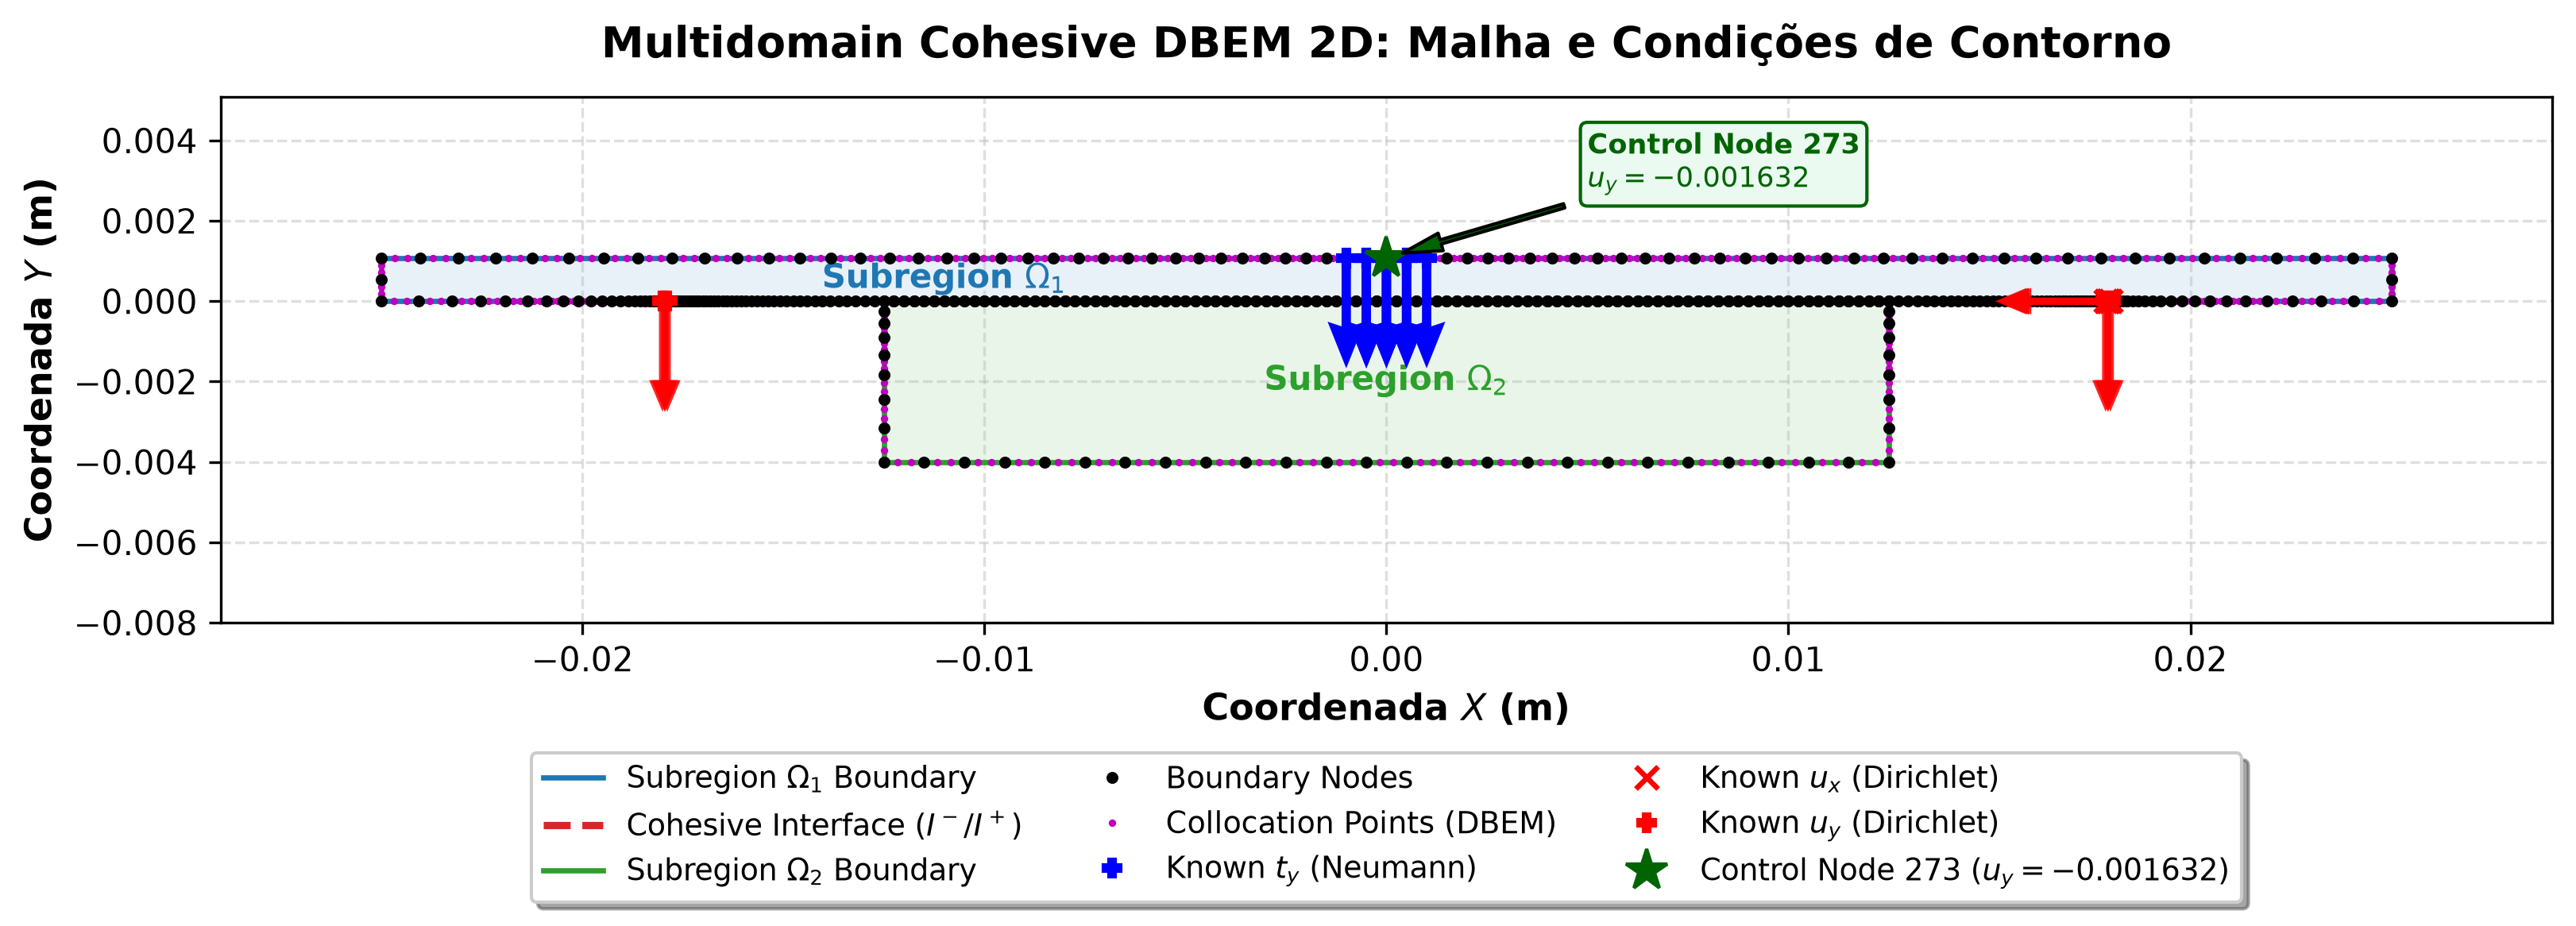

In [4]:
# 1. Definição das condições de contorno por Physical Curve
bound_cond = {
    'contorno_livre_sub': {'surface_type': 'B'},
    'apoio_esq':           {'surface_type': 'B', 'Uy': 0.0},             # Rolete à esquerda (Uy = 0)
    'apoio_dir':           {'surface_type': 'B', 'Ux': 0.0, 'Uy': 0.0},  # Apoio fixo à direita (Ux = Uy = 0)
    'carga':               {'surface_type': 'B', 'Ty': -1.0},            # Tração de referência Ty = -1.0 MPa (escalonada por lambda)
    'interface_m':         {'surface_type': 'Im'},
    'interface_p':         {'surface_type': 'Ip'},
    'contorno_livre_adh':  {'surface_type': 'B'},
}

# 2. Leitura da malha com meshio
comp_data = compute_inodes(model_base, bound_cond)
coords = comp_data['coordinates']
line_elems = comp_data['line_elements']
segments = comp_data['segments']
tag_to_curve = comp_data['tag_to_curve']

n_elem = len(line_elems)
n_nodes_raw = len(coords)

# 3. Identificação automática do nó central superior (x = 0, y = hs) para controle de deslocamento
dist_top_center = np.hypot(coords[:, 0] - 0.0, coords[:, 1] - 0.00108)
controlled_node_id = int(np.argmin(dist_top_center) + 1)

# 4. Identificação automática do nó coesivo na quina esquerda da interface (x = -12.5 mm, y = 0)
dist_left_corner = np.hypot(coords[:, 0] - (-0.0125), coords[:, 1] - 0.0)
cohesive_node_id = int(np.argmin(dist_left_corner) + 1)

print(f"[+] Malha extraída: {n_elem} elementos de contorno | {n_nodes_raw} nós geométricos ({2*n_nodes_raw} pontos de colocação DBEM)")
print(f"[+] Nó estrutural controlado (x=0, y=hs):     Nó {controlled_node_id} -> coord = ({coords[controlled_node_id-1,0]*1e3:.2f}, {coords[controlled_node_id-1,1]*1e3:.2f}) mm")
print(f"[+] Nó coesivo monitorado (x=-12.5mm, y=0):   Nó {cohesive_node_id}  -> coord = ({coords[cohesive_node_id-1,0]*1e3:.2f}, {coords[cohesive_node_id-1,1]*1e3:.2f}) mm")

# 5. Propriedades dos materiais e da lei coesiva bilinear (Tabela 2, Tabela 3 e Tabela 4 - Asymmetric)
materials = {
    'subregions': {
        1: {'E': 136.0e3, 'nu': 0.33},  # Substrato Alumínio 2024-T3 (E ajustado por b1/b2 = 2) [MPa]
        2: {'E': 3.0e3,   'nu': 0.35},  # Adesivo DGEBA/DETA/Organosilane [MPa]
    },
    'cohesive_mode_I': {
        'Kn0':  2.0e6,     # 2000 MPa/mm = 2.0e6 MPa/m
        'phin': 0.000520,  # Gc = 0.520 N/mm = 0.000520 MPa.m
        'smax': 44.654,    # sigma_c = 44.654 MPa
    },
    'cohesive_mode_II': {
        'Kto':  2.0e6,     # 2000 MPa/mm = 2.0e6 MPa/m
        'phit': 0.000520,  # Gc = 0.520 N/mm = 0.000520 MPa.m
        'tmax': 44.654,    # tau_c = 44.654 MPa
    }
}

# 6. Parâmetros da Análise Não Linear Assimétrica (CA)
# Incremento por passo: du = -2.40 mm / 50 = -0.048 mm/passo -> 34 passos cobrem até u = 1.632 mm
analysis_params = {
    'N_GAUSS': 200,
    'CP_DISTANCING': 0.0,
    'PLANE_STATE': 'PT',        # Estado Plano de Tensão (Plane Stress - Seção 6.1)
    'ANALYSIS_TYPE': 'CA',      # CA = Cohesive Asymmetric debonding (Seção 6.3.2)
    'Ns': 34,                   # 34 passos de 0.048 mm (até 1.632 mm)
    'tol_Newton': 1.0e-2,       # Tolerância de convergência do resíduo normalizado
    'itemax': 100000,           # Limite máximo de iterações por passo
    'structural_node': controlled_node_id,
    'cohesive_node': cohesive_node_id,
    'control': {
        'type': 'U',
        'node': controlled_node_id,
        'direction': 2,         # Direção vertical Y
        'value': -1.632e-3      # Deslocamento final prescrito em metros (-1.632 mm)
    }
}

inp_config = {
    'file_name': model_base,
    'materials': materials,
    'bound_cond': bound_cond,
    'element_specific_bc': {},
    'analysis_params': analysis_params
}

# 7. Gerar os 5 arquivos .txt de entrada do Fortran na pasta sim_fig26_nlinear/
create_fortran_input_files(sim_dir, comp_data, inp_config)

# 8. Visualizar a malha e as condições de contorno não lineares
parsed_bc = read_mesh_and_bcs(sim_dir)
bc_img_path = "mesh_and_boundary_conditions_nlinear.png"
show_dbem_geometry_and_bcs(parsed_bc, bc_img_path, show_node_ids=False, show_elem_ids=False)
display(Image(filename=bc_img_path))

## Passo 5: Execução Incremental do Solver Não Linear (`MAIN_COHESIVE_DBEM_2D`)

Durante a execução do solver na pasta `sim_fig26_nlinear/`:
1. As matrizes fundamentais $\mathbf{H}$ e $\mathbf{G}$ ($1780 \times 1780$) são integradas em paralelo com OpenMP em **$\approx 2.1\text{ s}$**;
2. Nos passos elásticos iniciais (Passos 1 a 13, até o pico de carga), nenhuma mola coesiva rompe ($\delta \le \delta_e$), de modo que a fatoração LU inicial da matriz $\mathbf{A}$ é reaproveitada diretamente e cada passo de carga converge em **1 única iteração ($\approx 7\text{ ms}$ por passo)**;
3. A partir do Passo 14 ($u = 0.672\text{ mm}$), o critério de início de dano é atingido na extremidade esquerda ($x = -12.5\text{ mm}$) e a trinca propaga-se de forma instável ao longo da interface, exigindo iterações de Newton-Raphson com atualização da matriz secante $\mathbf{A}(\mathbf{K}_c)$ até atingir o equilíbrio em cada passo incremental.

Ao final da execução, o solver gera os seguintes arquivos de saída:
- `6_OUTPUT_COLLOCATION_POINTS_COORDINATES.txt`: coordenadas $(x, y)$ dos 890 pontos de colocação descontínuos;
- `7_OUTPUT_ANALYSIS_TIME.txt`: número de iterações de Newton-Raphson em cada passo e tempos detalhados de montagem e fatoração;
- `8_OUTPUT_NODAL_STRUCTURAL_RESPONSE.txt`: histórico de deslocamentos $(u_x, u_y)$ em mm e trações escalonadas $(\lambda t_x, \lambda t_y)$ em MPa no nó estrutural monitorado (`Nó 273`);
- `9_OUTPUT_COHESIVE_RESPONSE.txt`: evolução de $(K_{nn}, K_{nt}, K_{tn}, K_{tt}, \delta_n, \delta_t)$ no nó coesivo monitorado;
- `10_OUTPUT_COHESIVE_STIFFNESS.txt`: rigidezes atuais $(K_{nn}, K_{tt})$ de todos os 890 nós para cada um dos $N_s$ passos de carga.

In [5]:
exe_abs = os.path.abspath(exe_name)
print(f"[*] Executando análise não linear assimétrica (CA) em '{sim_dir}'...")
t0 = time.time()
res_run = subprocess.run([exe_abs], cwd=sim_dir, capture_output=True, text=True)
t1 = time.time()

if res_run.returncode != 0:
    print(res_run.stdout)
    print(res_run.stderr)
    raise RuntimeError(f"Erro na execução do solver Fortran (código {res_run.returncode}).")

print(res_run.stdout.strip())
print(f"[+] Simulação não linear concluída com sucesso em {t1 - t0:.2f} segundos!")

# Resumo das iterações de Newton-Raphson registradas em 7_OUTPUT_ANALYSIS_TIME.txt
time_file = os.path.join(sim_dir, "7_OUTPUT_ANALYSIS_TIME.txt")
if os.path.exists(time_file):
    with open(time_file, "r") as f:
        t_lines = [l.strip() for l in f if l.strip()]
    iter_rows = [l.split() for l in t_lines if l[0].isdigit() and len(l.split()) >= 8]
    print(f"[+] Total de passos de carga resolvidos: {analysis_params['Ns']}")
    print(f"[+] Total acumulado de iterações de Newton-Raphson: {len(iter_rows)}")

[*] Executando análise não linear assimétrica (CA) em 'sim_fig26_nlinear'...
The number of processors available =            8
   The number of threads available    =            8
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 SOLUTION IS DONE
 
 
 COMPUTATIONAL WORK, SECONDS    0.923510E+02
[+] Simulação não linear concluída com sucesso em 92.35 segundos!
[+] Total de passos de carga resolvidos: 34
[+] Total acumulado de iterações de Newton-Raphson: 158


## Passo 6: Pós-Processamento e Geração da Fig. 26 ($h_s = 1.08\text{ mm}$)

### 6.1 Cálculo da Força Vertical Resultante $F\text{ (N)}$ a partir da Resposta Nodal (`8_OUTPUT_NODAL_STRUCTURAL_RESPONSE.txt`)
O arquivo `8_OUTPUT_NODAL_STRUCTURAL_RESPONSE.txt` registra, ao final de cada passo convergido $k = 1, \dots, N_s$, quatro colunas referentes ao nó estrutural monitorado (`Nó 273`, no centro da superfície de carga):
1. **Coluna 1 (`Ux`)**: $1000 \cdot u_x\text{ [mm]}$;
2. **Coluna 2 (`Uy`)**: $1000 \cdot u_y\text{ [mm]}$ (negativo no sentido descendente $\implies d = -u_y\text{ [mm]}$);
3. **Coluna 3 (`Tx`)**: $\lambda \cdot \overline{t}_x\text{ [MPa]}$;
4. **Coluna 4 (`Ty`)**: $\lambda \cdot \overline{t}_y\text{ [MPa]}$ (como $\overline{t}_y = -1.0\text{ MPa}$, a Coluna 4 vale $-\lambda\text{ [MPa]} = -\lambda\text{ [N/mm}^2\text{]}$).

Como a região de aplicação da carga central possui largura $w_{\text{load}} = 2.0\text{ mm}$ ($x \in [-1.0, +1.0]\text{ mm}$) e a largura transversal da interface colada no modelo 2D é $b = 5.0\text{ mm}$ (**Seção 3.1, Fig. 2a e Seção 6.2, página 12 do artigo**), a área carregada efetiva é:

$$A_{\text{load}} = w_{\text{load}} \times b = 2.0\text{ mm} \times 5.0\text{ mm} = 10.0\text{ mm}^2$$

Portanto, a força vertical resultante $F$ em **Newtons (N)** em cada passo de carga é obtida diretamente por:

$$F\text{ [N]} = |\lambda \overline{t}_y| \times A_{\text{load}} = -10.0 \times (\text{Coluna 4})$$

Passo | Deslocamento Central u (mm) | Força Resultante F (N) | Regime        
----------------------------------------------------------------------
    0 |                      0.0000 |                   0.00 | Inicial       
    1 |                      0.0480 |                  14.92 | Elástico      
    2 |                      0.0960 |                  29.84 | Elástico      
    3 |                      0.1440 |                  44.75 | Elástico      
    4 |                      0.1920 |                  59.67 | Elástico      
    5 |                      0.2400 |                  74.59 | Elástico      
    6 |                      0.2880 |                  89.51 | Elástico      
    7 |                      0.3360 |                 104.43 | Elástico      
    8 |                      0.3840 |                 119.35 | Elástico      
    9 |                      0.4320 |                 134.26 | Elástico      
   10 |                      0.4800 |                 149.18 | Elástico

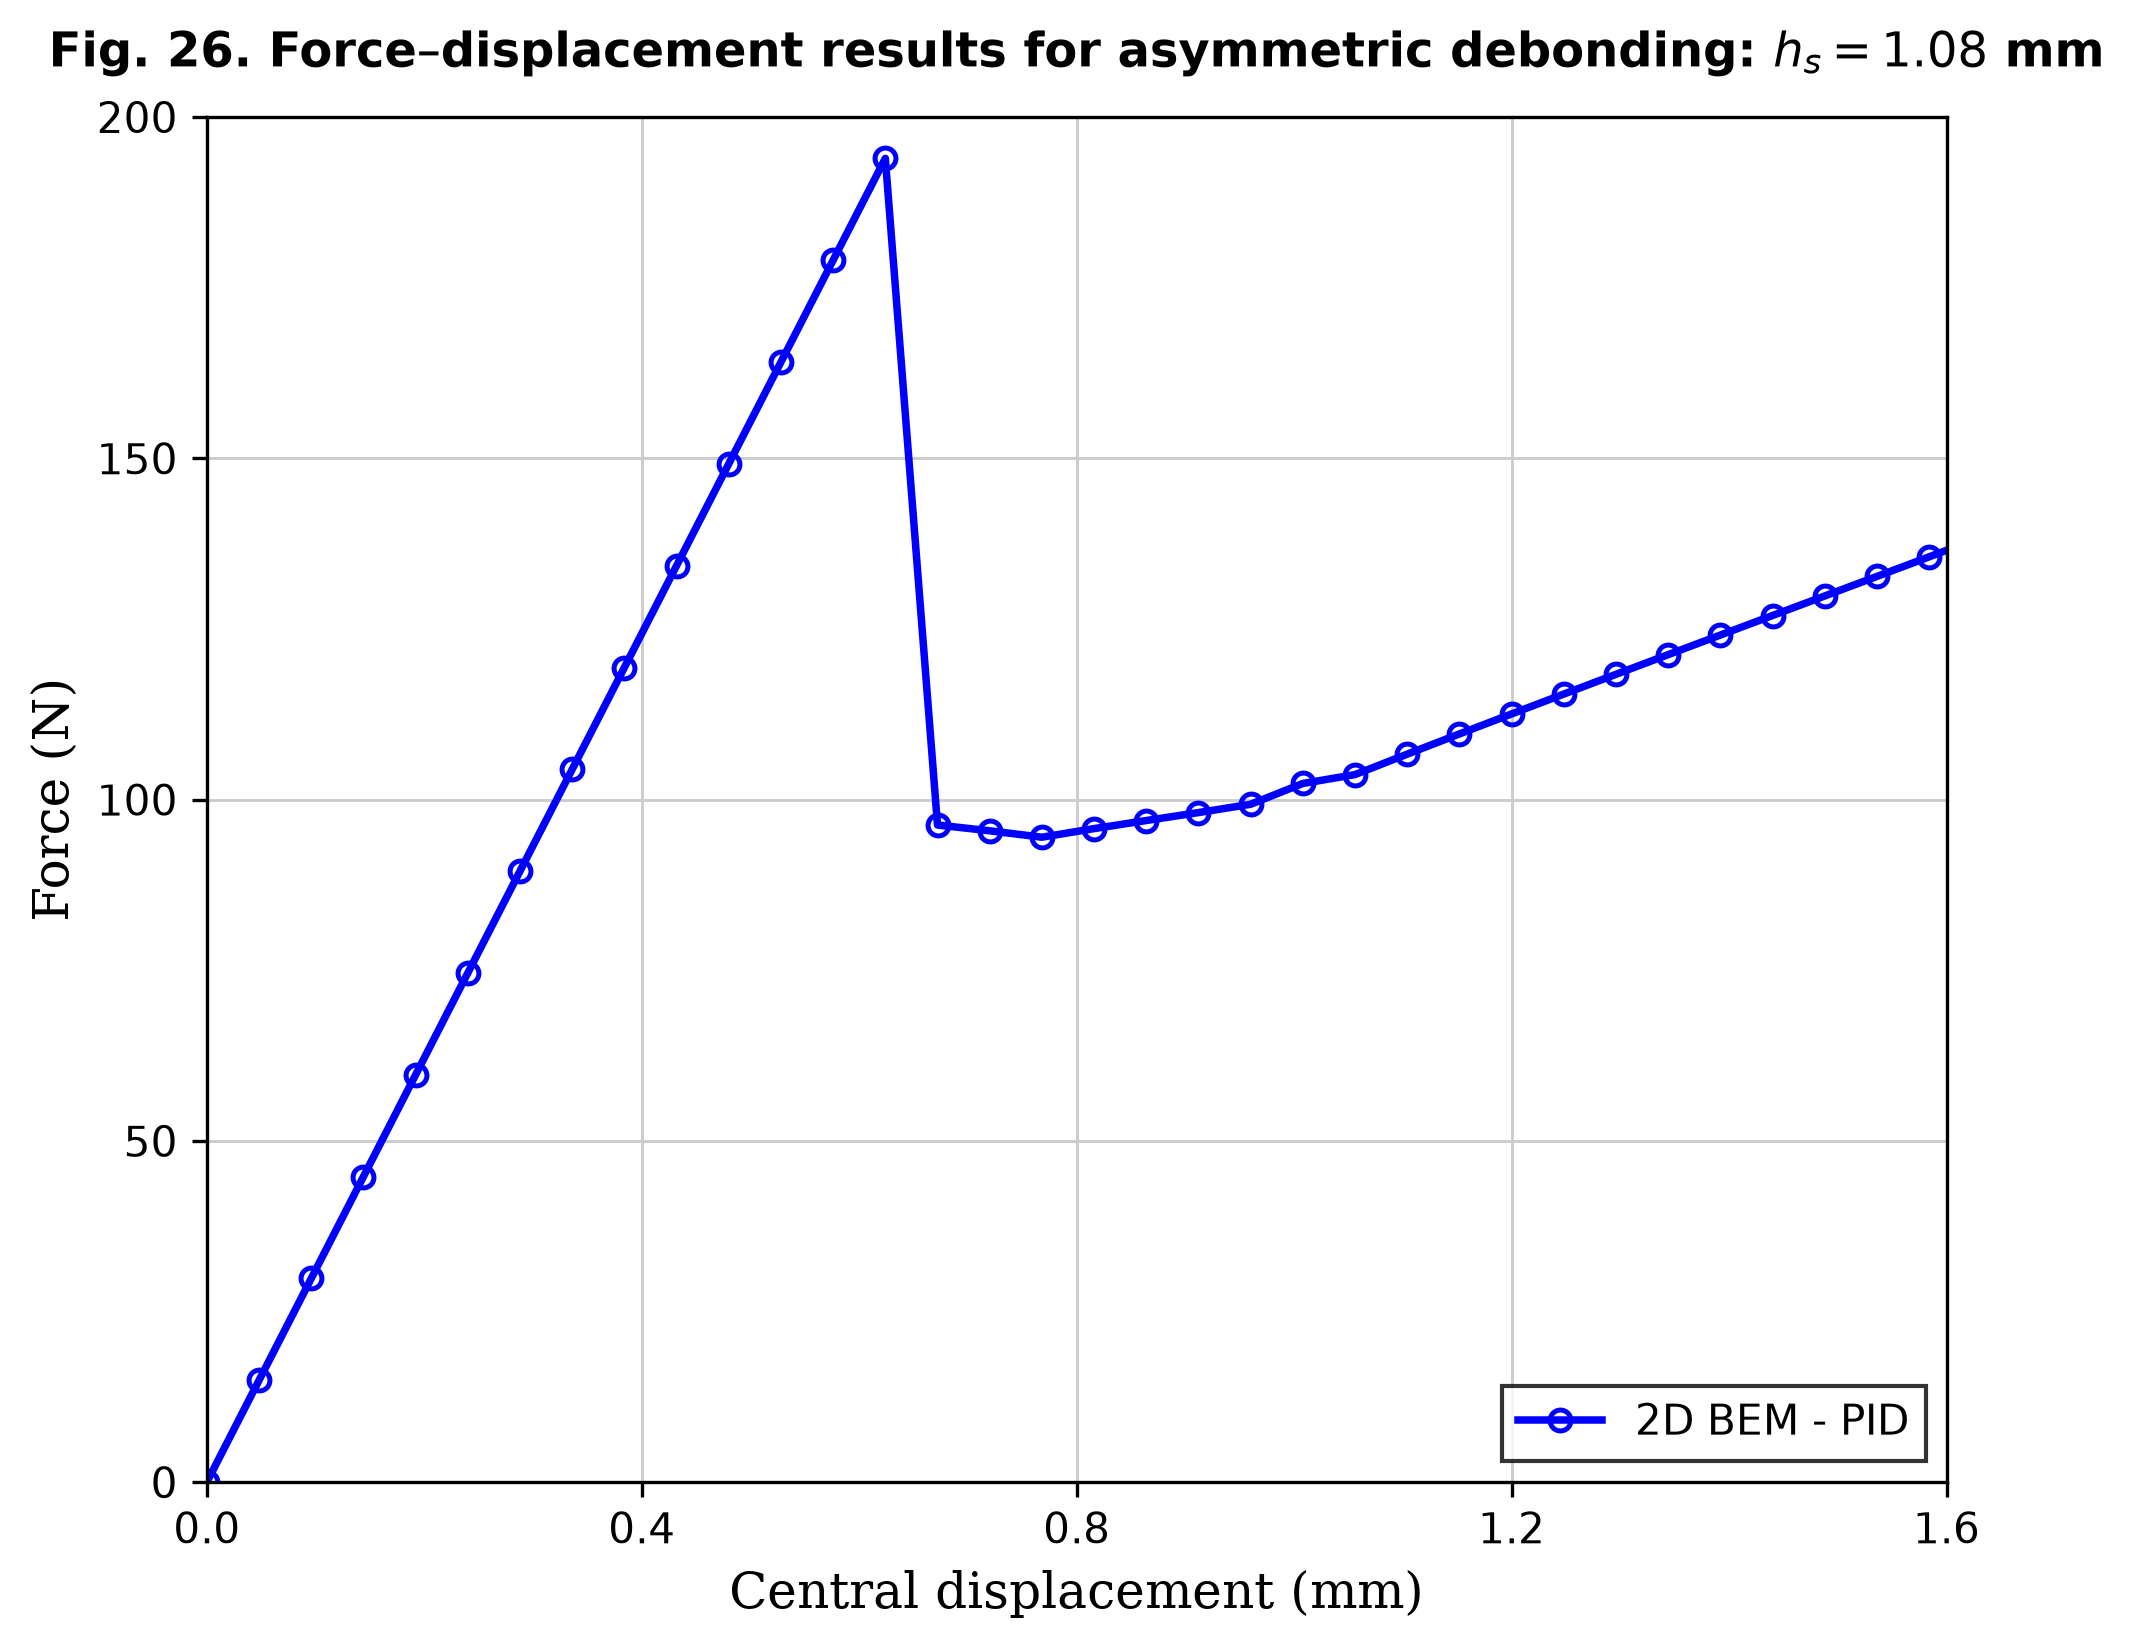

In [6]:
# 1. Leitura da resposta estrutural nodal (8_OUTPUT_NODAL_STRUCTURAL_RESPONSE.txt)
resp_file = os.path.join(sim_dir, "8_OUTPUT_NODAL_STRUCTURAL_RESPONSE.txt")
struct_data = np.loadtxt(resp_file, skiprows=1)

# Adiciona a origem (u = 0, F = 0)
u_mm = np.concatenate([[0.0], -struct_data[:, 1]])
w_load_mm = 2.0
b_width_mm = 5.0
A_load_mm2 = w_load_mm * b_width_mm  # 10.0 mm^2
F_N = np.concatenate([[0.0], -A_load_mm2 * struct_data[:, 3]])

# 2. Tabela passo a passo da análise não linear
print("======================================================================")
print(f"{'Passo':>5s} | {'Deslocamento Central u (mm)':>27s} | {'Força Resultante F (N)':>22s} | {'Regime':<14s}")
print("----------------------------------------------------------------------")
for idx in range(len(u_mm)):
    if idx == 0:
        regime = "Inicial"
    elif idx <= 13:
        regime = "Elástico / Pico" if idx == 13 else "Elástico"
    elif idx == 14:
        regime = "Queda Brusca"
    else:
        regime = "Propagação PID"
    print(f"{idx:5d} | {u_mm[idx]:27.4f} | {F_N[idx]:22.2f} | {regime:<14s}")
print("======================================================================")
print(f"[Resumo] Força crítica de pico (Fc): {F_N.max():.2f} N em u = {u_mm[F_N.argmax()]:.4f} mm")
print(f"[Resumo] Rigidez global inicial (K_over): {F_N[12]/u_mm[12]:.2f} N/mm (Experimental: 309 ± 9 N/mm)")
print(f"[Resumo] Força mínima logo após propagação inicial: {F_N[13:].min():.2f} N em u = {u_mm[13 + F_N[13:].argmin()]:.4f} mm")
print(f"[Resumo] Força no deslocamento u = 1.584 mm: {F_N[33]:.2f} N")

# 3. Geração da Fig. 26 (somente curva 2D BEM - PID)
fig, ax = plt.subplots(figsize=(6.8, 5.6), dpi=300)
ax.plot(
    u_mm, F_N, '-o',
    color='blue', linewidth=1.8, markersize=5.0,
    markerfacecolor='none', markeredgecolor='blue', markeredgewidth=1.2,
    label='2D BEM - PID'
)

ax.set_xlim(0.0, 1.6)
ax.set_ylim(0.0, 200.0)
ax.set_xticks([0.0, 0.4, 0.8, 1.2, 1.6])
ax.set_yticks([0, 50, 100, 150, 200])
ax.grid(True, linestyle='-', color='#cccccc', linewidth=0.7)
ax.set_xlabel('Central displacement (mm)', fontsize=12, fontfamily='serif')
ax.set_ylabel('Force (N)', fontsize=12, fontfamily='serif')
ax.set_title(
    r'Fig. 26. Force–displacement results for asymmetric debonding: $h_s = 1.08$ mm',
    fontsize=11.5, fontweight='bold', pad=12
)
ax.legend(loc='lower right', frameon=True, edgecolor='black', fancybox=False, fontsize=10)

plt.tight_layout()
fig26_path = "fig26_force_displacement_hs108.png"
plt.savefig(fig26_path, dpi=300, bbox_inches='tight')
plt.close(fig)

display(Image(filename=fig26_path))

## Passo 7: Diagnóstico Físico do Dano Coesivo (Evolução do Comprimento da Trinca e Degradação de Rigidez)

A partir do arquivo `10_OUTPUT_COHESIVE_STIFFNESS.txt` e das coordenadas dos pontos de colocação em `6_OUTPUT_COLLOCATION_POINTS_COORDINATES.txt`, podemos extrair duas informações fundamentais sobre a cinemática da fratura assimétrica:

1. **Evolução do Comprimento da Trinca $a\text{ (mm)}$ vs. Deslocamento Central $u\text{ (mm)}$** (comparável à curva `PID asymmetric` da **Fig. 30**, página 17 do artigo):
   - Até $u = 0.624\text{ mm}$ (pico de carga), a trinca possui comprimento $a = 0\text{ mm}$;
   - No passo seguinte ($u = 0.672\text{ mm}$), ocorre nucleação e salto brusco da trinca assimétrica para $a \approx 8.2\text{ mm}$ a partir da borda esquerda ($x = -12.5\text{ mm}$);
   - Em seguida, a trinca cresce de maneira progressiva e estável até $a \approx 15.2\text{ mm}$ em $u = 1.60\text{ mm}$.
2. **Frente de Degradação da Rigidez Normalizada $K_{nn}(x) / k_{n0}$ ao Longo da Interface**:
   - Mostra claramente a transição entre a região descolada à esquerda ($K_{nn}/k_{n0} \approx 0$, trinca livre de tração) e a região íntegra à direita ($K_{nn}/k_{n0} = 1$), avançando da esquerda para a direita à medida que o deslocamento central imposto aumenta.

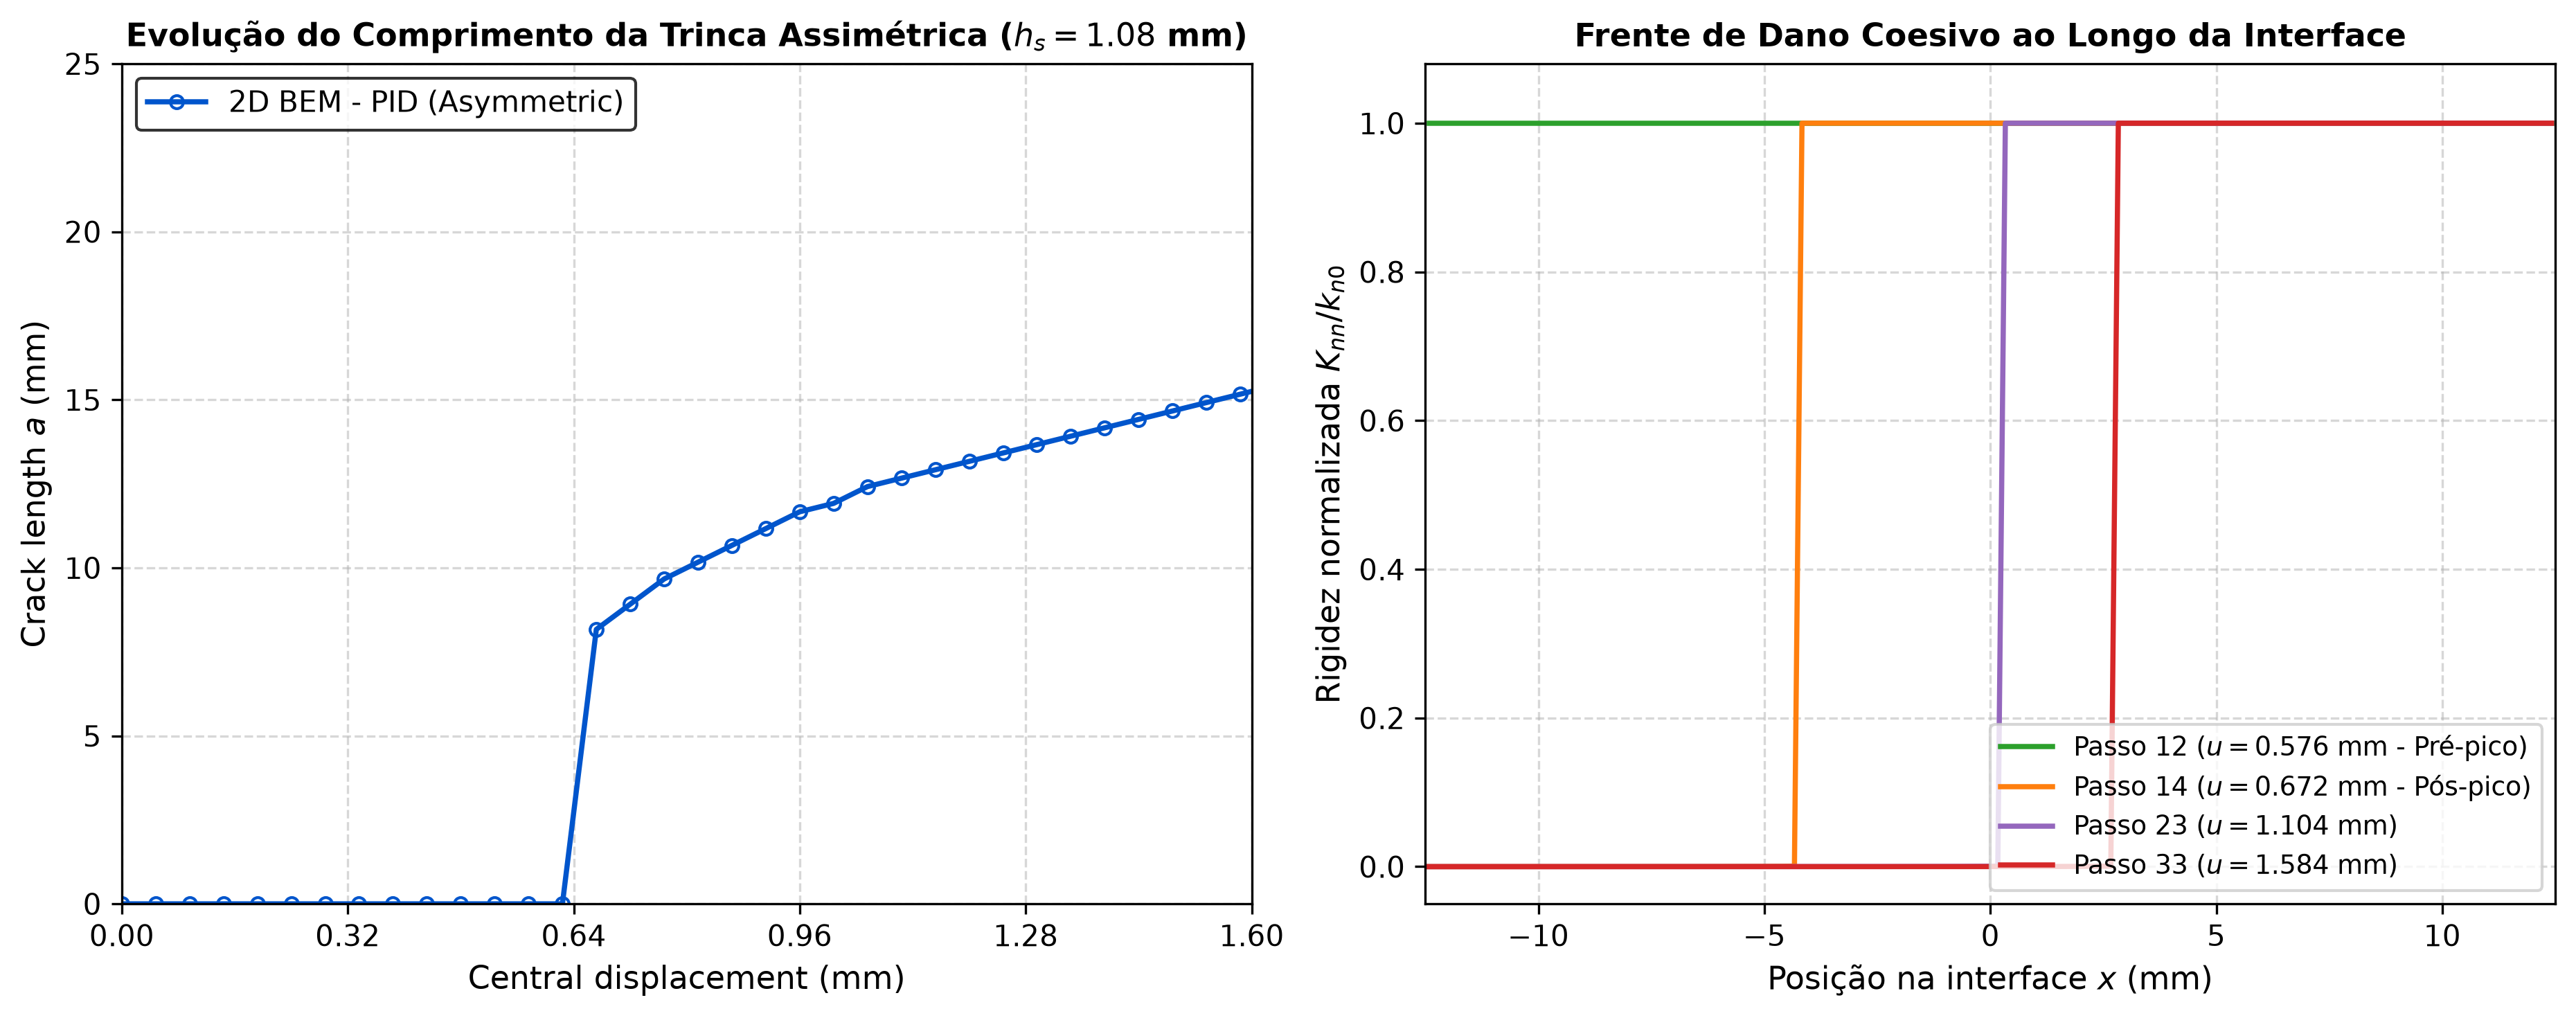

In [7]:
fcoords = np.loadtxt(os.path.join(sim_dir, "6_OUTPUT_COLLOCATION_POINTS_COORDINATES.txt"))
stiff_data = np.loadtxt(os.path.join(sim_dir, "10_OUTPUT_COHESIVE_STIFFNESS.txt"), skiprows=1)
n_steps = len(struct_data)
nnodes = len(stiff_data) // n_steps
steps_stiff = stiff_data.reshape(n_steps, nnodes, 3)

x_all = fcoords[:, 0] * 1000.0  # Coordenada X em mm
crack_len = [0.0]
for st_idx in range(n_steps):
    st = steps_stiff[st_idx]
    broken = np.where((st[:, 1] > 0) & (st[:, 1] < 1.0e4))[0]
    if len(broken) > 0:
        xb_max = x_all[broken].max()
        a_mm = max(0.0, xb_max - (-12.5))
    else:
        a_mm = 0.0
    crack_len.append(a_mm)

fig2, axes = plt.subplots(1, 2, figsize=(12.5, 5.0), dpi=300)

# Subplot esquerdo: Comprimento da trinca vs deslocamento central (análogo à Fig. 30 do artigo)
axes[0].plot(
    u_mm, crack_len, '-o',
    color='#0055cc', linewidth=1.8, markersize=4.5,
    markerfacecolor='none', label='2D BEM - PID (Asymmetric)'
)
axes[0].set_xlim(0.0, 1.6)
axes[0].set_ylim(0.0, 25.0)
axes[0].set_xticks([0.0, 0.32, 0.64, 0.96, 1.28, 1.60])
axes[0].set_yticks([0, 5, 10, 15, 20, 25])
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].set_xlabel('Central displacement (mm)', fontsize=11)
axes[0].set_ylabel(r'Crack length $a$ (mm)', fontsize=11)
axes[0].set_title(r'Evolução do Comprimento da Trinca Assimétrica ($h_s = 1.08$ mm)', fontsize=11, fontweight='bold')
axes[0].legend(loc='upper left', frameon=True, edgecolor='black')

# Subplot direito: Perfil de rigidez normalizada Knn / kn0 ao longo da interface
int_nodes = np.where(steps_stiff[0, :, 1] > 0)[0]
x_int = x_all[int_nodes]
order_idx = np.argsort(x_int)
x_sorted = x_int[order_idx]

for step_num, col, lbl in [
    (12, '#2ca02c', f'Passo 12 ($u = {u_mm[12]:.3f}$ mm - Pré-pico)'),
    (14, '#ff7f0e', f'Passo 14 ($u = {u_mm[14]:.3f}$ mm - Pós-pico)'),
    (23, '#9467bd', f'Passo 23 ($u = {u_mm[23]:.3f}$ mm)'),
    (33, '#d62728', f'Passo 33 ($u = {u_mm[33]:.3f}$ mm)')
]:
    knn_norm = steps_stiff[step_num - 1, int_nodes[order_idx], 1] / 2.0e6
    axes[1].plot(x_sorted, knn_norm, '-', color=col, linewidth=1.8, label=lbl)

axes[1].set_xlim(-12.5, 12.5)
axes[1].set_ylim(-0.05, 1.08)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].set_xlabel(r'Posição na interface $x$ (mm)', fontsize=11)
axes[1].set_ylabel(r'Rigidez normalizada $K_{nn} / k_{n0}$', fontsize=11)
axes[1].set_title('Frente de Dano Coesivo ao Longo da Interface', fontsize=11, fontweight='bold')
axes[1].legend(loc='lower right', frameon=True, fontsize=9)

plt.tight_layout()
evol_path = "fig26_cohesive_damage_evolution_hs108.png"
plt.savefig(evol_path, dpi=300, bbox_inches='tight')
plt.close(fig2)

display(Image(filename=evol_path))